In [1]:
# Demo

# Overview
- MNIST dataset
  + Goal: recognizing handwritten digits
  + Input: a 28x28 image
  + Output: class label (0, 1,..., 9)
- Defining an MLP for MNIST
- Training and evaluating an MLP

# Import libraries

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

num_classes = 10
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


# (1) Data

In [3]:
transform = transforms.ToTensor()  # Chuyển ảnh PIL [0, 255] sang tensor float32 [0.0, 1.0] shape (1, 28, 28)

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(len(train_dataset), "train samples")
print(len(test_dataset), "test samples")

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.12MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 123kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.33MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.27MB/s]

60000 train samples
10000 test samples


# (2) Declare model

In [4]:
class MnistMLP(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 512)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(0.2)
        self.fc2 = nn.Linear(512, 512)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(0.2)
        self.fc3_10ways_logits = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.flatten(x)
        x = self.dropout1(self.relu1(self.fc1(x)))
        feat = self.dropout2(self.relu2(self.fc2(x)))
        logits = self.fc3_10ways_logits(feat)
        return logits

model = MnistMLP(num_classes=num_classes).to(device)
print(model)

MnistMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=512, bias=True)
  (relu1): ReLU()
  (dropout1): Dropout(p=0.2, inplace=False)
  (fc2): Linear(in_features=512, out_features=512, bias=True)
  (relu2): ReLU()
  (dropout2): Dropout(p=0.2, inplace=False)
  (fc3_10ways_logits): Linear(in_features=512, out_features=10, bias=True)
)


# (3) Train defined model
- Note that the training history including loss and accuracy will be save in 'history' variable
- In case your system runs out of memory (OOM), try to decrease batch size

In [5]:
lr = 0.01
epochs = 30
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
starting_time = time.time()

for epoch in range(1, epochs + 1):
    model.train()
    tr_loss, tr_correct, tr_total = 0.0, 0, 0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        logits = model(bx)
        loss = criterion(logits, by)
        loss.backward()
        optimizer.step()

        tr_loss += loss.item() * by.size(0)
        tr_correct += (logits.argmax(dim=1) == by).sum().item()
        tr_total += by.size(0)

    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for bx, by in test_loader:
            bx, by = bx.to(device), by.to(device)
            logits = model(bx)
            loss = criterion(logits, by)
            val_loss += loss.item() * by.size(0)
            val_correct += (logits.argmax(dim=1) == by).sum().item()
            val_total += by.size(0)

    epoch_tr_loss = tr_loss / tr_total
    epoch_tr_acc = tr_correct / tr_total
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = val_correct / val_total

    history["train_loss"].append(epoch_tr_loss)
    history["train_acc"].append(epoch_tr_acc)
    history["val_loss"].append(epoch_val_loss)
    history["val_acc"].append(epoch_val_acc)

    print(
        f"Epoch {epoch:02d}/{epochs:02d} - "
        f"loss: {epoch_tr_loss:.4f} - acc: {epoch_tr_acc:.4f} - "
        f"val_loss: {epoch_val_loss:.4f} - val_acc: {epoch_val_acc:.4f}"
    )

print("> training time is %.4f minutes" % ((time.time() - starting_time) / 60))

Epoch 01/30 - loss: 2.1215 - acc: 0.4757 - val_loss: 1.6957 - val_acc: 0.7128
Epoch 02/30 - loss: 1.1161 - acc: 0.7540 - val_loss: 0.6744 - val_acc: 0.8417
Epoch 03/30 - loss: 0.6123 - acc: 0.8329 - val_loss: 0.4711 - val_acc: 0.8768
Epoch 04/30 - loss: 0.4873 - acc: 0.8615 - val_loss: 0.3945 - val_acc: 0.8928
Epoch 05/30 - loss: 0.4315 - acc: 0.8768 - val_loss: 0.3555 - val_acc: 0.9007
Epoch 06/30 - loss: 0.3941 - acc: 0.8864 - val_loss: 0.3327 - val_acc: 0.9034
Epoch 07/30 - loss: 0.3689 - acc: 0.8935 - val_loss: 0.3115 - val_acc: 0.9104
Epoch 08/30 - loss: 0.3486 - acc: 0.8992 - val_loss: 0.2955 - val_acc: 0.9157
Epoch 09/30 - loss: 0.3326 - acc: 0.9038 - val_loss: 0.2829 - val_acc: 0.9189
Epoch 10/30 - loss: 0.3151 - acc: 0.9086 - val_loss: 0.2705 - val_acc: 0.9215
Epoch 11/30 - loss: 0.3038 - acc: 0.9118 - val_loss: 0.2608 - val_acc: 0.9265
Epoch 12/30 - loss: 0.2914 - acc: 0.9161 - val_loss: 0.2492 - val_acc: 0.9299
Epoch 13/30 - loss: 0.2798 - acc: 0.9194 - val_loss: 0.2412 - va

### Training time
- Training time with GTX 1080 is about 1.4402 minutes for 30 epochs
- Training time with Core i7 is around 3.0493 minutes for 30 epochs

# (4) Evaluate trained model

In [6]:
model.eval()
total_loss, total_correct, total_samples = 0.0, 0, 0
with torch.no_grad():
    for bx, by in test_loader:
        bx, by = bx.to(device), by.to(device)
        logits = model(bx)
        loss = criterion(logits, by)
        total_loss += loss.item() * by.size(0)
        total_correct += (logits.argmax(dim=1) == by).sum().item()
        total_samples += by.size(0)

print("Test loss:", total_loss / total_samples)
print("Test accuracy:", total_correct / total_samples)

Test loss: 0.14270118538439275
Test accuracy: 0.9567


# Predict a random test image & inspect intermediate feature from fc2

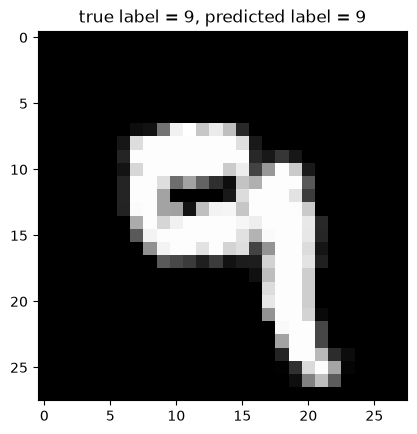

probs shape: (1, 10) | sum: [1.]
fc2 feature shape: (1, 512)


In [7]:

random_test_index = np.random.choice(len(test_dataset), size=1)[0]
test_img_tensor, test_label = test_dataset[random_test_index]
test_img_2d = test_img_tensor.squeeze(0).numpy()

features_cache = {}
def hook_fc2(module, inp, out):
    features_cache["fc2"] = out.detach().cpu().numpy()

handle = model.fc2.register_forward_hook(hook_fc2)

model.eval()
with torch.no_grad():
    input_batch = test_img_tensor.unsqueeze(0).to(device)  # shape (1, 1, 28, 28)
    logits = model(input_batch)
    probs = torch.softmax(logits, dim=1).cpu().numpy()
    pred_label = int(np.argmax(probs, axis=1)[0])

handle.remove()

plt.imshow(test_img_2d, cmap="gray")
plt.title(f"true label = {test_label}, predicted label = {pred_label}")
plt.show()

print("probs shape:", probs.shape, "| sum:", np.sum(probs, axis=1))
print("fc2 feature shape:", features_cache["fc2"].shape)